# 02 — Machine Measurements Audit: `29999` Sentinels, `int16` Overflows & Derived Intervals

`machine_measurements.csv` provides `9` numerical ECG measurements (`rr_interval`, `p_onset`, `p_end`, `qrs_onset`, `qrs_end`, `t_end`, `p_axis`, `qrs_axis`, `t_axis`) for all `800,035` studies — **with zero `NaN`s**, because missing or failed measurements are encoded as numeric **sentinel values** (`29999`) or **`16-bit` integer overflows** (`65535`, `65534`, `32767`, `-32768`)!

This notebook audits:
1. Exact counts of `== 29999` sentinels and `int16`/`uint16` overflows in every column.
2. Why `p_onset` (`123k`) and `p_end` (`230k`) hit `29999` so often (strongly enriched in Atrial Fibrillation & paced rhythms where P-waves are absent!).
3. Derived clinical intervals (**HR**, **PR**, **QRS**, **QT**, **QTc Bazett**) before vs after cleaning sentinels and flagging impossible values.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "mimic_iv_ecg" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate mimic_iv_ecg/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from mimic_iv_ecg import MIMICIVECGDataset

MIMIC_DIR = REPO_ROOT / "mimic_iv_ecg"
DATA_DIR = MIMIC_DIR / "data"
QUALITY_DIR = MIMIC_DIR / "quality"
LEADS = MIMICIVECGDataset.LEADS

num_cols = ["rr_interval", "p_onset", "p_end", "qrs_onset", "qrs_end", "t_end", "p_axis", "qrs_axis", "t_axis"]
mm = pd.read_csv(DATA_DIR / "machine_measurements.csv", usecols=num_cols + ["report_0", "report_1"])

rows = []
for c in num_cols:
    s = mm[c]
    n_29999 = int((s == 29999).sum())
    s_no29 = s[s != 29999]
    is_axis = c.endswith("_axis")
    n_overflow = int((s_no29.lt(-180) | s_no29.gt(360)).sum()) if is_axis else int((s_no29.le(0) | s_no29.gt(5000)).sum())
    s_clean = s_no29[(s_no29.between(-180, 360) if is_axis else s_no29.between(1, 5000))]
    rows.append({
        "column": c,
        "== 29999": n_29999,
        "% 29999": round(n_29999 / len(mm) * 100, 2),
        "overflow_or_<=0": n_overflow,
        "raw_min": float(s.min()),
        "raw_max": float(s.max()),
        "clean_p50": round(float(s_clean.median()), 1),
        "clean_p05_p95": f"[{s_clean.quantile(0.05):.0f}, {s_clean.quantile(0.95):.0f}]",
    })
audit_tbl = pd.DataFrame(rows)
display(audit_tbl)

,column,== 29999,% 29999,overflow_or_<=0,raw_min,raw_max,clean_p50,clean_p05_p95
0,rr_interval,1336,0.17,194,0.0,65535.0,810.0,"[512, 1153]"
1,p_onset,123434,15.43,21,0.0,29999.0,40.0,"[40, 357]"
2,p_end,230323,28.79,128,0.0,61440.0,150.0,"[116, 176]"
3,qrs_onset,1132,0.14,219,0.0,29999.0,200.0,"[156, 505]"
4,qrs_end,1318,0.16,140,0.0,65534.0,302.0,"[244, 604]"
5,t_end,1344,0.17,10,235.0,29999.0,610.0,"[496, 913]"
6,p_axis,123354,15.42,7658,-31248.0,32767.0,51.0,"[-5, 79]"
7,qrs_axis,2458,0.31,1106,-180.0,32767.0,13.0,"[-63, 80]"
8,t_axis,2458,0.31,2150,-32768.0,32767.0,42.0,"[-60, 134]"


p_onset == 29999 rate in Sinus/All : 15.4%
p_onset == 29999 rate in AF        : 90.3%
p_onset == 29999 rate in Paced     : 78.0%


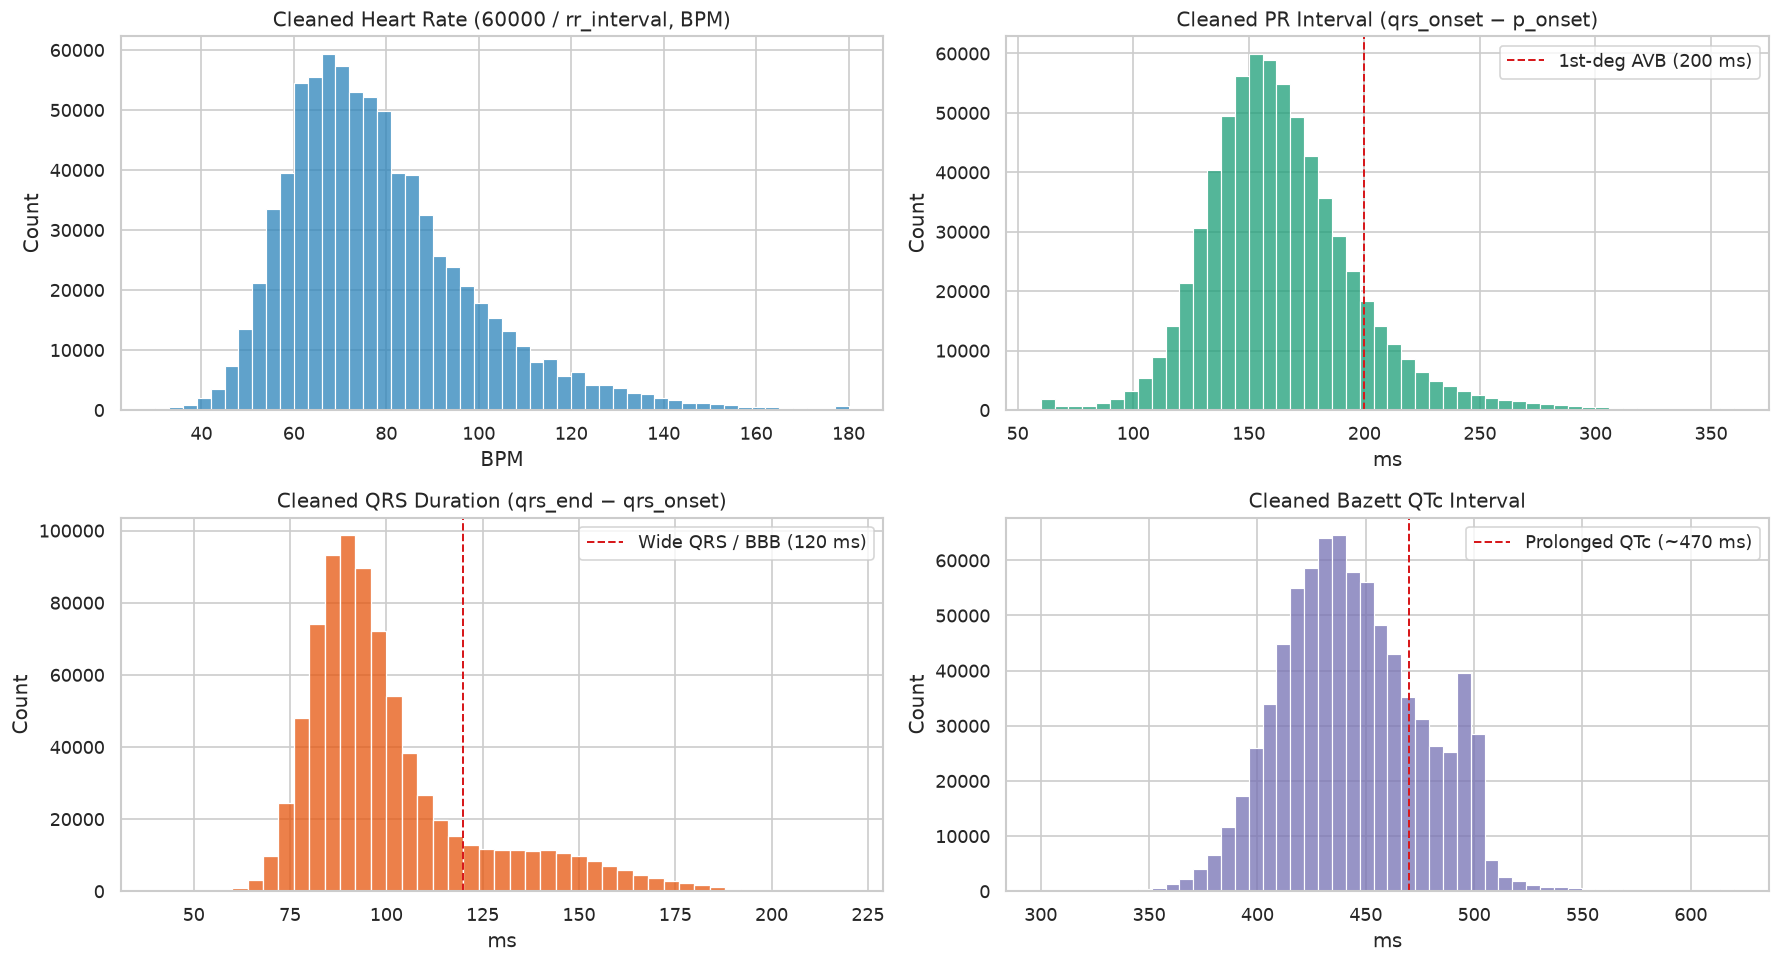

In [2]:
# Derived physiological intervals after cleaning 29999 & overflows
m = mm[num_cols].replace(29999, np.nan)
m["rr_clean"] = m["rr_interval"].where(m["rr_interval"].between(200, 3000))
m["hr_bpm"]   = 60000.0 / m["rr_clean"]
m["qrs_ms"]   = (m["qrs_end"] - m["qrs_onset"]).where((m["qrs_end"] - m["qrs_onset"]).between(30, 300))
m["pr_ms"]    = (m["qrs_onset"] - m["p_onset"]).where((m["qrs_onset"] - m["p_onset"]).between(50, 500))
m["qt_ms"]    = (m["t_end"] - m["qrs_onset"]).where((m["t_end"] - m["qrs_onset"]).between(180, 750))
m["qtc_ms"]   = m["qt_ms"] / np.sqrt(m["rr_clean"] / 1000.0)

# Check AF / Paced enrichment inside p_onset == 29999
rep01 = (mm["report_0"].fillna("") + " | " + mm["report_1"].fillna("")).str.lower()
is_af = rep01.str.contains("atrial fibrillation", regex=False)
is_paced = rep01.str.contains("paced|pacemaker", regex=True)
print(f"p_onset == 29999 rate in Sinus/All : {(mm['p_onset'] == 29999).mean()*100:.1f}%")
print(f"p_onset == 29999 rate in AF        : {(mm.loc[is_af, 'p_onset'] == 29999).mean()*100:.1f}%")
print(f"p_onset == 29999 rate in Paced     : {(mm.loc[is_paced, 'p_onset'] == 29999).mean()*100:.1f}%")

fig, axes = plt.subplots(2, 2, figsize=(15, 8.2))
sns.histplot(m["hr_bpm"].dropna().clip(30, 180), bins=50, color="#2b83ba", ax=axes[0, 0])
axes[0, 0].set_title("Cleaned Heart Rate (60000 / rr_interval, BPM)")
axes[0, 0].set_xlabel("BPM")

sns.histplot(m["pr_ms"].dropna().clip(60, 360), bins=50, color="#1b9e77", ax=axes[0, 1])
axes[0, 1].axvline(200, color="#d7191c", ls="--", lw=1.2, label="1st-deg AVB (200 ms)")
axes[0, 1].set_title("Cleaned PR Interval (qrs_onset − p_onset)")
axes[0, 1].set_xlabel("ms"); axes[0, 1].legend()

sns.histplot(m["qrs_ms"].dropna().clip(40, 220), bins=45, color="#e6550d", ax=axes[1, 0])
axes[1, 0].axvline(120, color="#d7191c", ls="--", lw=1.2, label="Wide QRS / BBB (120 ms)")
axes[1, 0].set_title("Cleaned QRS Duration (qrs_end − qrs_onset)")
axes[1, 0].set_xlabel("ms"); axes[1, 0].legend()

sns.histplot(m["qtc_ms"].dropna().clip(300, 620), bins=50, color="#7570b3", ax=axes[1, 1])
axes[1, 1].axvline(470, color="#d7191c", ls="--", lw=1.2, label="Prolonged QTc (~470 ms)")
axes[1, 1].set_title("Cleaned Bazett QTc Interval")
axes[1, 1].set_xlabel("ms"); axes[1, 1].legend()

plt.tight_layout()
plt.show()